In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('gurgaon_properties_13k_outlier_treated_facing_filled.csv')

In [4]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet a...,3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,900.0,Super Built up area 1380(128.21 sq.m.)Built Up...,2,2,3,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220


In [5]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                     0
price_per_sqft            0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
floorNum                 19
facing                    0
agePossession             0
super_built_up_area    5028
built_up_area          8716
carpet_area            5323
study room                0
servant room              0
store room                0
pooja room                0
others                    0
furnishing_type           0
luxury_score              0
dtype: int64

## built_up_area

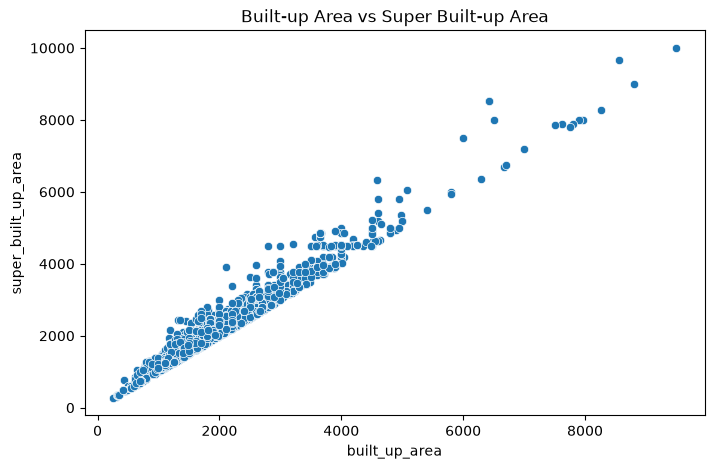

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['built_up_area'], y=df['super_built_up_area'])
plt.title('Built-up Area vs Super Built-up Area')
plt.show()

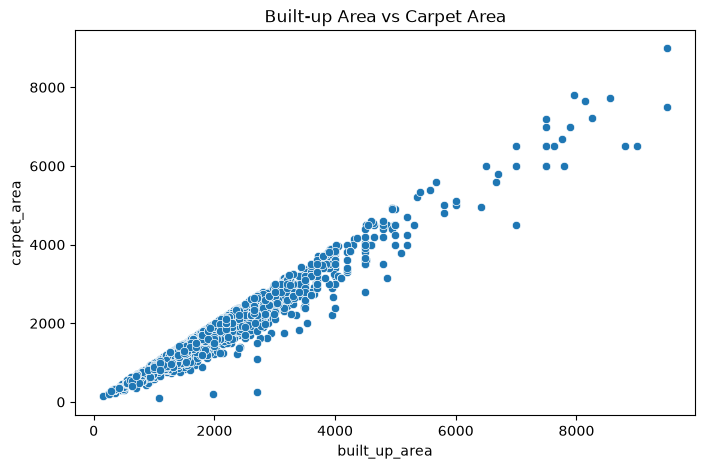

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['built_up_area'], y=df['carpet_area'])
plt.title('Built-up Area vs Carpet Area')
plt.show()

In [8]:
((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull())).sum()

np.int64(0)

In [9]:
all_present_df = df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))]

In [10]:
all_present_df.shape

(2347, 23)

In [11]:
super_to_built_up_ratio = (all_present_df['super_built_up_area'] / all_present_df['built_up_area']).median()

In [12]:
carpet_to_built_up_ratio = (all_present_df['carpet_area'] / all_present_df['built_up_area']).median()

In [13]:
print(super_to_built_up_ratio, carpet_to_built_up_ratio)

1.1111111111111112 0.8888888888888888


In [14]:
# Both super_built_up_area and carpet_area present, built_up_area is null
sbc_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())].copy()

In [15]:
sbc_df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet a...,3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
17,flat,mapsko casa bella,sector 82,0.86,8120.0,1059.0,Super Built up area 1430(132.85 sq.m.)Carpet a...,3,3,3,5.0,South,Moderately Old,1430.0,NaN,1056.00,1,0,0,0,0,1,149
26,flat,shapoorji pallonji joyville gurugram,sector 102,2.03,12000.0,1692.0,Super Built up area 1692(157.19 sq.m.)Carpet a...,3,3,2,1.0,North-East,New Property,1692.0,NaN,1027.68,0,0,0,0,0,0,75
38,flat,mapsko mount ville,sector 79,1.28,8557.0,1496.0,Super Built up area 1490(138.43 sq.m.)Carpet a...,3,3,3,16.0,South,Relatively New,1490.0,NaN,1063.91,1,0,0,0,0,1,160
45,flat,bptp terra,sector 37d,1.80,8215.0,2191.0,Super Built up area 2191(203.55 sq.m.)Carpet a...,4,3,3,18.0,North-West,Relatively New,2191.0,NaN,1860.00,1,1,0,1,0,1,57


In [16]:
sbc_df['built_up_area'] = sbc_df['built_up_area'].fillna(
    round(((sbc_df['super_built_up_area'] / super_to_built_up_ratio) + (sbc_df['carpet_area'] / carpet_to_built_up_ratio)) / 2)
)

In [17]:
df.update(sbc_df)

In [18]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                     0
price_per_sqft            0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
floorNum                 19
facing                    0
agePossession             0
super_built_up_area    5028
built_up_area          6718
carpet_area            5323
study room                0
servant room              0
store room                0
pooja room                0
others                    0
furnishing_type           0
luxury_score              0
dtype: int64

In [19]:
# super_built_up_area present, carpet_area is null, built_up_area is null
sb_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull())].copy()

In [20]:
sb_df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
5,flat,signature global solera,sector 107,0.50,7692.0,650.0,Super Built up area 546(50.73 sq.m.),2,2,1,11.0,North-East,Relatively New,546.0,NaN,NaN,0,0,0,0,0,0,63
7,flat,sushant lok 1 builder floors,sector 43,2.50,12920.0,1935.0,Super Built up area 215(179.77 sq.m.),3,3,2,2.0,East,New Property,1935.0,NaN,NaN,0,0,0,0,0,0,214
8,flat,tata primanti,sector 72,3.40,15560.0,2185.0,Super Built up area 2185(202.99 sq.m.),3,4,3+,9.0,North,Moderately Old,2185.0,NaN,NaN,0,1,0,0,0,0,70


In [21]:
sb_df['built_up_area'] = sb_df['built_up_area'].fillna(round(sb_df['super_built_up_area'] / super_to_built_up_ratio))

In [22]:
df.update(sb_df)

In [23]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                     0
price_per_sqft            0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
floorNum                 19
facing                    0
agePossession             0
super_built_up_area    5028
built_up_area          3102
carpet_area            5323
study room                0
servant room              0
store room                0
pooja room                0
others                    0
furnishing_type           0
luxury_score              0
dtype: int64

In [24]:
# super_built_up_area is null, carpet_area present, built_up_area is null
c_df = df[(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())].copy()

In [25]:
c_df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
11,flat,signature global solera,sector 107,0.35,6489.0,539.0,Carpet area: 547 (50.82 sq.m.),2,2,2,8.0,North-West,Relatively New,NaN,NaN,547.0,0,0,0,0,0,0,67
14,flat,signature global park,sohna road,0.83,7410.0,1120.0,Carpet area: 1120 (104.05 sq.m.),3,2,2,1.0,South,New Property,NaN,NaN,1120.0,0,0,0,0,0,0,33
16,flat,gls arawali homes,sohna road,0.28,5982.0,468.0,Carpet area: 468 (43.48 sq.m.),2,2,2,3.0,East,Relatively New,NaN,NaN,468.0,0,0,0,0,0,0,50
18,flat,trisara our homes 3,sohna road,0.34,5405.0,629.0,Carpet area: 629 (58.44 sq.m.),2,2,1,0.0,North,New Property,NaN,NaN,629.0,0,0,0,0,0,0,57
21,flat,vatika independent floors,sector 82,1.16,6987.0,1660.0,Carpet area: 1660 (154.22 sq.m.),3,3,3+,1.0,South-East,Relatively New,NaN,NaN,1660.0,0,1,1,1,0,1,200


In [26]:
c_df['built_up_area'] = c_df['built_up_area'].fillna(round(c_df['carpet_area'] / carpet_to_built_up_ratio))

In [27]:
df.update(c_df)

In [28]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                     0
price_per_sqft            0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
floorNum                 19
facing                    0
agePossession             0
super_built_up_area    5028
built_up_area             0
carpet_area            5323
study room                0
servant room              0
store room                0
pooja room                0
others                    0
furnishing_type           0
luxury_score              0
dtype: int64

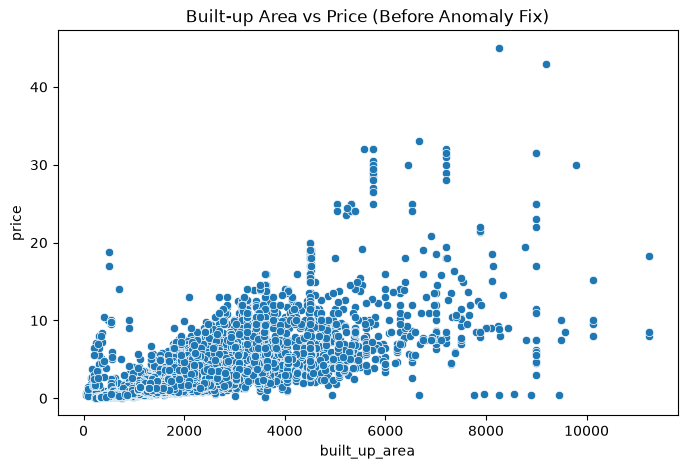

In [29]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['built_up_area'], y=df['price'])
plt.title('Built-up Area vs Price (Before Anomaly Fix)')
plt.show()

In [30]:
anamoly_df = df[(df['built_up_area'] < 2000) & (df['price'] > 2.5)][['price', 'area', 'built_up_area']].copy()

In [32]:
anamoly_df.sample(5)

,price,area,built_up_area
5248,3.50,2200.0,1980.0
10684,3.40,2200.0,1980.0
9467,4.00,1519.0,1709.0
11296,3.30,1944.0,1944.0
1280,2.69,2152.0,1935.0


In [33]:
anamoly_df['built_up_area'] = anamoly_df['area']

In [34]:
df.update(anamoly_df)

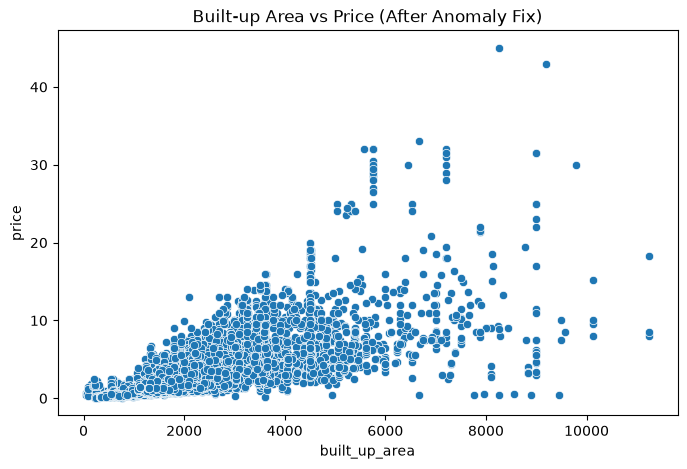

In [35]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['built_up_area'], y=df['price'])
plt.title('Built-up Area vs Price (After Anomaly Fix)')
plt.show()

In [36]:
cols_to_drop = [c for c in ['area', 'areaWithType', 'super_built_up_area', 'carpet_area', 'area_room_ratio'] if c in df.columns]
df.drop(columns=cols_to_drop, inplace=True)

In [37]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,8,8,2,3.0,East,Moderately Old,2520.0,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,3,3,3,6.0,South,Relatively New,1553.0,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,3,3,1,6.0,North-West,Relatively New,2574.0,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,2,3,3+,4.0,West,Relatively New,1567.0,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,2,2,3,10.0,South-East,Relatively New,1310.0,0,0,0,0,1,0,220


In [38]:
df.isnull().sum()

property_type       0
society             1
sector              0
price               0
price_per_sqft      0
bedRoom             0
bathroom            0
balcony             0
floorNum           19
facing              0
agePossession       0
built_up_area       0
study room          0
servant room        0
store room          0
pooja room          0
others              0
furnishing_type     0
luxury_score        0
dtype: int64

## floorNum & society

In [39]:
df[df['floorNum'].isnull()]

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
152,house,independent,sector 24,1.45,2984.0,3,3,1,NaN,South-East,Old Property,540.0,0,0,0,0,0,0,9
179,house,independent,sector 25,13.00,45710.0,6,8,3+,NaN,East,Relatively New,2844.0,1,1,1,1,0,2,0
496,house,independent,sector 26,4.60,12198.0,4,4,3+,NaN,North-East,Old Property,3771.0,0,0,0,0,0,0,28
504,flat,experion heartsong,sector 108,1.08,6150.0,3,3,0,NaN,North-East,Under Construction,1758.0,0,0,0,0,0,0,0
560,house,jacob pura,sector 12,0.35,9722.0,2,1,0,NaN,North-East,Old Property,360.0,0,0,0,0,0,0,0
699,house,vipul tatvam villa,sector 48,8.50,26235.0,4,4,2,NaN,East,Moderately Old,3240.0,0,1,1,1,0,0,103
935,house,vipul tatvam villa,sector 48,8.50,26235.0,4,4,1,NaN,North,Relatively New,3240.0,0,0,0,0,0,0,27
985,house,ansal sushant lok,sector 43,10.50,27911.0,4,4,2,NaN,North-East,Old Property,3762.0,0,1,0,0,0,0,87
1101,house,dlf new town heights,sector 86,2.47,7718.0,4,4,3+,NaN,West,Moderately Old,2800.0,0,1,0,1,0,1,164
1686,house,independent,sector 7,6.50,15046.0,3,2,3+,NaN,North-East,Old Property,4320.0,0,0,0,0,0,0,9


In [40]:
house_floor_median = df[df['property_type'] == 'house']['floorNum'].median()
house_floor_median

np.float64(2.0)

In [41]:
df['floorNum'] = df['floorNum'].fillna(house_floor_median)

In [42]:
df.isnull().sum()

property_type      0
society            1
sector             0
price              0
price_per_sqft     0
bedRoom            0
bathroom           0
balcony            0
floorNum           0
facing             0
agePossession      0
built_up_area      0
study room         0
servant room       0
store room         0
pooja room         0
others             0
furnishing_type    0
luxury_score       0
dtype: int64

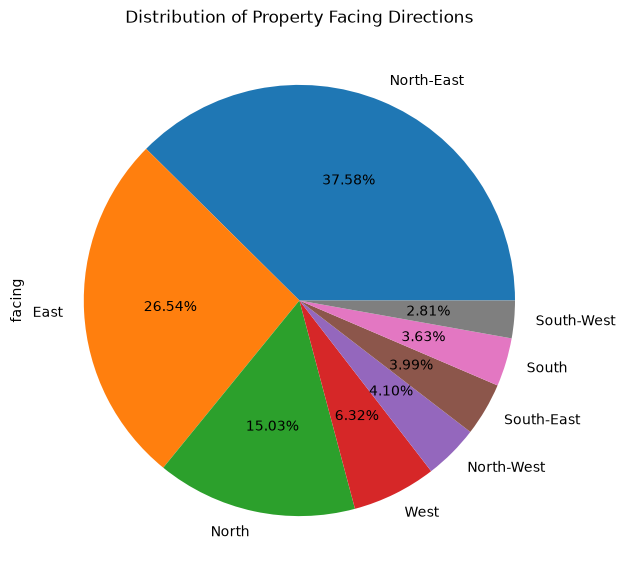

In [43]:
plt.figure(figsize=(7, 7))
df['facing'].value_counts().plot(kind='pie', autopct='%0.2f%%')
plt.ylabel('facing')
plt.title('Distribution of Property Facing Directions')
plt.show()

In [44]:
df.drop(index=df[df['society'].isnull()].index, inplace=True)

In [45]:
df.isnull().sum()

property_type      0
society            0
sector             0
price              0
price_per_sqft     0
bedRoom            0
bathroom           0
balcony            0
floorNum           0
facing             0
agePossession      0
built_up_area      0
study room         0
servant room       0
store room         0
pooja room         0
others             0
furnishing_type    0
luxury_score       0
dtype: int64

## agePossession

In [46]:
df['agePossession'].value_counts()

agePossession
Relatively New        4876
New Property          3149
Under Construction    2026
Moderately Old        1941
Old Property           907
Undefined              290
Name: count, dtype: int64

In [47]:
df[df['agePossession'] == 'Undefined'].head(10)

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
20,house,ansal celebrity homes,sector 2,5.20,10000.0,4,5,2,1.0,North-East,Undefined,5200.0,0,0,0,0,0,0,0
30,flat,m3m skywalk,sector 74,1.78,12500.0,2,2,3+,12.0,North,Undefined,1602.0,0,0,0,0,0,0,69
62,house,independent,sector 3,0.55,7333.0,1,1,0,1.0,North-East,Undefined,750.0,0,0,0,0,0,0,0
76,house,vipul world,sector 48,3.35,5583.0,6,5,3+,3.0,South,Undefined,6000.0,0,0,0,0,0,0,66
81,house,dlf the grove,sector 54,5.70,23457.0,4,4,0,1.0,North-East,Undefined,2430.0,0,0,0,0,0,0,60
98,flat,the serenas,sector 36,0.42,7910.0,2,2,1,3.0,North-East,Undefined,597.0,0,0,0,0,0,0,0
104,flat,ramprastha the edge towers,sector 37d,1.10,5528.0,3,3,3,9.0,North,Undefined,1990.0,0,0,0,0,0,0,69
118,flat,emaar mgf emerald floors,sector 65,2.60,15758.0,3,3,3+,3.0,East,Undefined,1650.0,0,0,0,0,0,0,181
119,flat,trisara our homes 3,sohna road,0.21,4339.0,1,1,0,2.0,North,Undefined,484.0,0,0,0,0,0,0,57
121,house,independent,sector 4,0.85,7522.0,3,3,0,1.0,North-East,Undefined,1130.0,0,0,0,0,0,0,0


In [48]:
def mode_based_imputation(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector']) & (df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0]
        else:
            return np.nan
    else:
        return row['agePossession']

In [49]:
df['agePossession'] = df.apply(mode_based_imputation, axis=1)

In [50]:
df['agePossession'].value_counts()

agePossession
Relatively New        5003
New Property          3172
Under Construction    2057
Moderately Old        1978
Old Property           940
Undefined               39
Name: count, dtype: int64

In [51]:
def mode_based_imputation2(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0]
        else:
            return np.nan
    else:
        return row['agePossession']

In [52]:
df['agePossession'] = df.apply(mode_based_imputation2, axis=1)

In [53]:
df['agePossession'].value_counts()

agePossession
Relatively New        5012
New Property          3172
Under Construction    2065
Moderately Old        1983
Old Property           940
Undefined               17
Name: count, dtype: int64

In [54]:
def mode_based_imputation3(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0]
        else:
            return np.nan
    else:
        return row['agePossession']

In [55]:
df['agePossession'] = df.apply(mode_based_imputation3, axis=1)

In [56]:
df['agePossession'].value_counts()

agePossession
Relatively New        5014
New Property          3172
Under Construction    2065
Moderately Old        1998
Old Property           940
Name: count, dtype: int64

In [57]:
df.shape

(13189, 19)

In [58]:
df.to_csv('gurgaon_properties_13k_missing_value_imputation.csv', index=False)